In [1]:
pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: C:\Users\gnfer\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


### **Preparação Inicial**
**Imports de blbliotecas e dos dados a partir dos ficheiros e preparação inicial dos dados**

In [2]:
# Importar bibliotecas

import scipy as sp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix
from sklearn.utils import resample

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import Perceptron
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler 

In [3]:
#Import the data
df_eda = pd.read_csv("combined_Lisboa_porto_complete.csv")
df_eda_untouched = df_eda.copy()

# Em vez de estarem na mesma pasta do notebook, podem usar o caminho absoluto do ficheiro

# Porquê .copy()? Porque queremos um objeto independente, não um apontador para df_titanic
# Assim, cria-se uma cópia independente de um objeto. Evita-se que alterações na cópia afetem o objeto original

# Ex.:
# >>> a = [1, 2]  # cria um objeto na memória que aponta para 1 e 2, e aponta a para ele
# >>> b = a       # aponta b para onde a aponta (porque a é um objeto mutável)
# >>> a[0] = 2    # altera o objeto para onde a aponta, direcionando o seu primeiro item para 2
# >>> a
# [2, 2]
# >>> b
# [2, 2]

In [4]:
# Check data structure
df_eda.head()

,city,datetime,CO,NO2,O3,PM10,PM2.5,SO2,temperature_c,humidity_percent,pressure_hpa,wind_speed_kmh,wind_direction_deg,precipitation_mm,label_air_good
0,Lisboa,2025-09-05 01:00:00,0.96,25.20,84.09,11.82,9.12,6.75,18.9,82.0,1018.5,16.2,357.0,0.0,Yes
1,Lisboa,2025-09-05 02:00:00,0.75,26.40,86.20,13.24,8.87,5.11,18.8,80.0,1018.3,15.5,356.0,0.0,Yes
2,Lisboa,2025-09-05 03:00:00,0.87,25.16,74.41,15.18,10.84,5.76,18.6,79.0,1017.4,11.5,2.0,0.0,Yes
3,Lisboa,2025-09-05 04:00:00,0.51,13.59,68.57,17.48,13.14,5.03,18.3,77.0,1017.2,11.3,351.0,0.0,No
4,Lisboa,2025-09-05 05:00:00,0.61,15.89,78.79,14.70,13.68,6.20,18.6,72.0,1016.8,9.4,356.0,0.0,Yes


In [5]:
# Informações gerais
# Verificar os tipos de dados e obter mais informações
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1442 entries, 0 to 1441
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   city                1442 non-null   object 
 1   datetime            1442 non-null   object 
 2   CO                  1442 non-null   float64
 3   NO2                 1442 non-null   float64
 4   O3                  1442 non-null   float64
 5   PM10                1442 non-null   float64
 6   PM2.5               1442 non-null   float64
 7   SO2                 1442 non-null   float64
 8   temperature_c       1442 non-null   float64
 9   humidity_percent    1442 non-null   float64
 10  pressure_hpa        1442 non-null   float64
 11  wind_speed_kmh      1442 non-null   float64
 12  wind_direction_deg  1442 non-null   float64
 13  precipitation_mm    1442 non-null   float64
 14  label_air_good      1442 non-null   object 
dtypes: float64(12), object(3)
memory usage: 169.1+ KB


In [6]:

# Estatísticas numéricas
# Looking for abnormal outliers
df_eda.describe()

,CO,NO2,O3,PM10,PM2.5,SO2,temperature_c,humidity_percent,pressure_hpa,wind_speed_kmh,wind_direction_deg,precipitation_mm
count,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000,1442.000000
mean,1.006546,29.701477,69.301706,21.614896,15.138800,6.453259,19.428502,69.087379,1019.587864,8.953051,234.529820,0.043967
std,0.442828,13.279275,16.780429,9.428184,6.889596,3.050010,3.778562,19.718614,3.062214,6.143344,122.062848,0.574530
min,0.120000,2.420000,28.220000,1.840000,0.100000,0.100000,10.000000,16.000000,1002.900000,0.000000,1.000000,0.000000
25%,0.650000,19.040000,56.552500,13.952500,9.650000,4.122500,17.000000,54.000000,1018.200000,3.700000,104.000000,0.000000
50%,0.940000,28.155000,69.205000,20.110000,14.080000,6.010000,19.200000,72.000000,1020.100000,7.300000,293.000000,0.000000
75%,1.300000,38.527500,81.310000,28.020000,19.940000,8.397500,21.700000,86.000000,1021.600000,13.000000,340.000000,0.000000
max,2.560000,76.470000,114.680000,58.570000,38.750000,18.360000,32.000000,100.000000,1025.700000,28.000000,360.000000,15.600000


In [7]:
# E as variáveis não numéricas, temos alguma informação sobre elas?

print('City Unique Values:', df_eda['city'].unique())
print('datetime Unique Values:', df_eda['datetime'].unique())
print('label_air_good Unique Values:', df_eda['label_air_good'].unique())
df_eda.describe(include=['O']) # estatísticas para variáveis do tipo string

City Unique Values: ['Lisboa' 'Porto']
datetime Unique Values: ['2025-09-05 01:00:00' '2025-09-05 02:00:00' '2025-09-05 03:00:00'
 '2025-09-05 04:00:00' '2025-09-05 05:00:00' '2025-09-05 06:00:00'
 '2025-09-05 07:00:00' '2025-09-05 08:00:00' '2025-09-05 09:00:00'
 '2025-09-05 10:00:00' '2025-09-05 11:00:00' '2025-09-05 12:00:00'
 '2025-09-05 13:00:00' '2025-09-05 14:00:00' '2025-09-05 15:00:00'
 '2025-09-05 16:00:00' '2025-09-05 17:00:00' '2025-09-05 18:00:00'
 '2025-09-05 19:00:00' '2025-09-05 20:00:00' '2025-09-05 21:00:00'
 '2025-09-05 22:00:00' '2025-09-05 23:00:00' '2025-09-06 00:00:00'
 '2025-09-06 01:00:00' '2025-09-06 02:00:00' '2025-09-06 03:00:00'
 '2025-09-06 04:00:00' '2025-09-06 05:00:00' '2025-09-06 06:00:00'
 '2025-09-06 07:00:00' '2025-09-06 08:00:00' '2025-09-06 09:00:00'
 '2025-09-06 10:00:00' '2025-09-06 11:00:00' '2025-09-06 12:00:00'
 '2025-09-06 13:00:00' '2025-09-06 14:00:00' '2025-09-06 15:00:00'
 '2025-09-06 16:00:00' '2025-09-06 17:00:00' '2025-09-06 18:00:00'

,city,datetime,label_air_good
count,1442,1442,1442
unique,2,721,2
top,Lisboa,2025-09-05 01:00:00,Yes
freq,721,2,958


In [8]:
df_eda.columns

Index(['city', 'datetime', 'CO', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
       'temperature_c', 'humidity_percent', 'pressure_hpa', 'wind_speed_kmh',
       'wind_direction_deg', 'precipitation_mm', 'label_air_good'],
      dtype='object')

In [9]:
# Vamos verificar valores em falta!
df_eda.isnull().sum()

city                  0
datetime              0
CO                    0
NO2                   0
O3                    0
PM10                  0
PM2.5                 0
SO2                   0
temperature_c         0
humidity_percent      0
pressure_hpa          0
wind_speed_kmh        0
wind_direction_deg    0
precipitation_mm      0
label_air_good        0
dtype: int64

### **Distribuição das Variáveis e Histogramas**

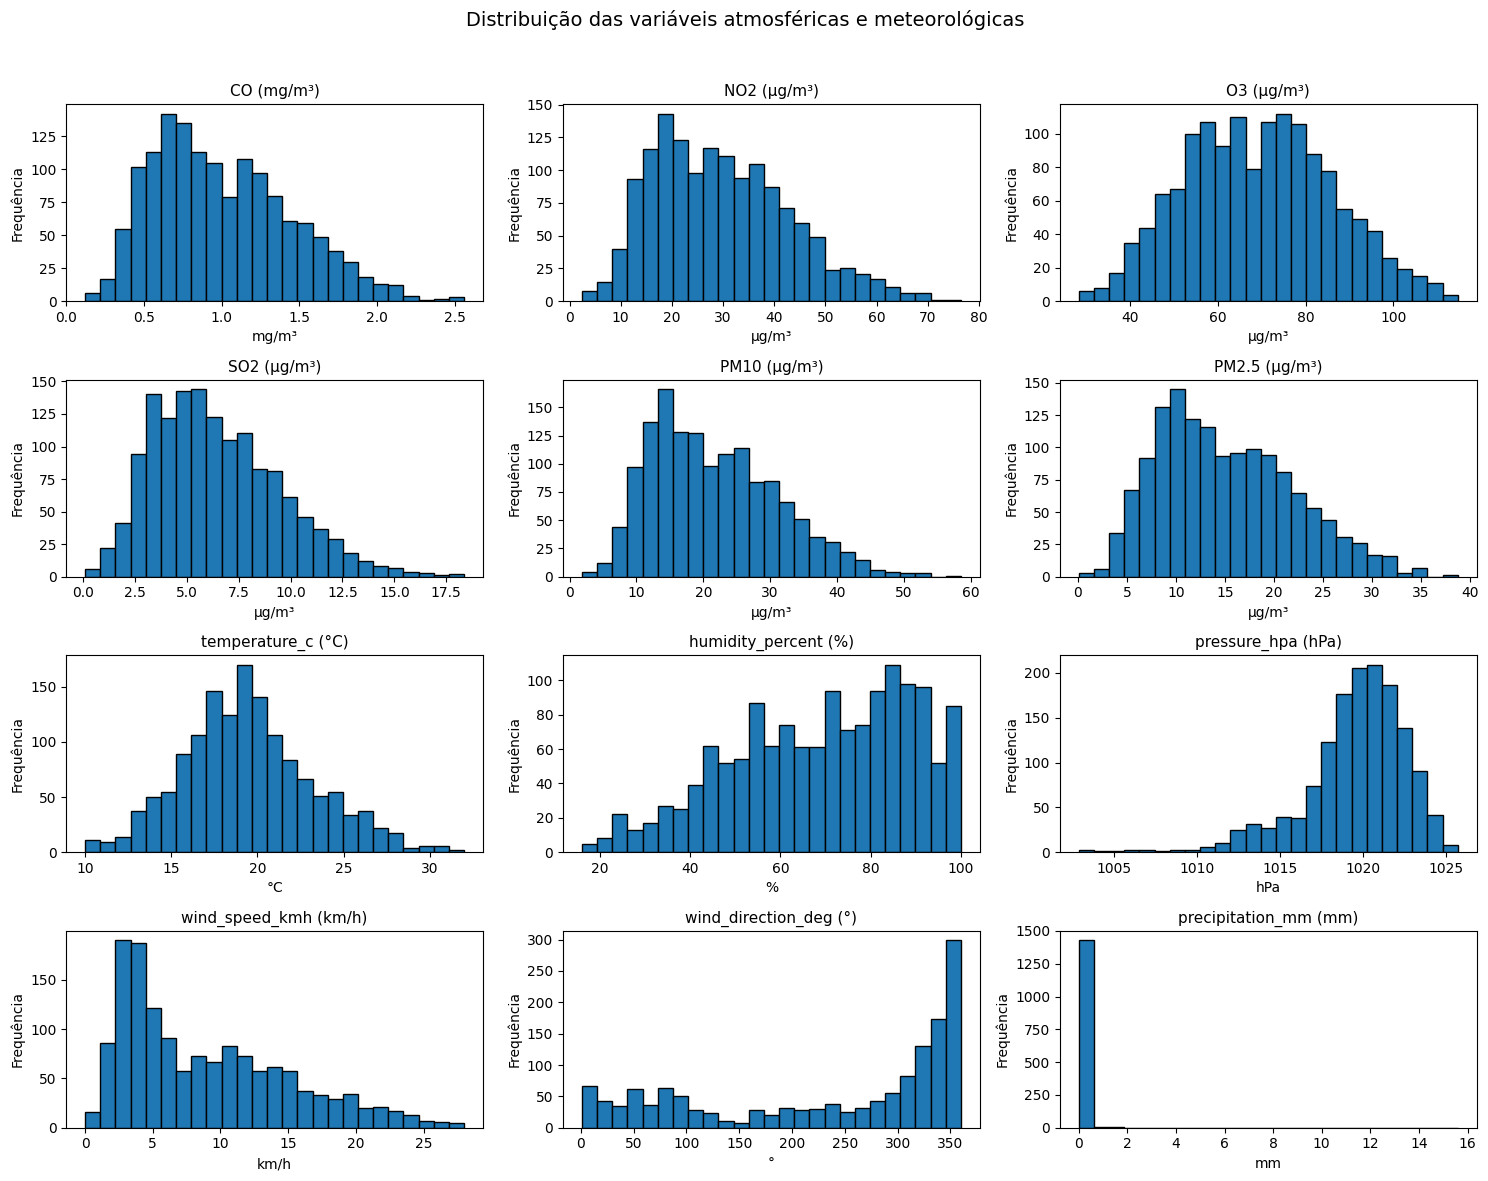

In [10]:
import matplotlib.pyplot as plt

# Dicionário com variáveis e unidades (atmosféricas + meteorológicas)
variaveis_unidades = {
    'CO': 'mg/m³',
    'NO2': 'µg/m³',
    'O3': 'µg/m³',
    'SO2': 'µg/m³',
    'PM10': 'µg/m³',
    'PM2.5': 'µg/m³',
    'temperature_c': '°C',
    'humidity_percent': '%',
    'pressure_hpa': 'hPa',
    'wind_speed_kmh': 'km/h',
    'wind_direction_deg': '°',
    'precipitation_mm': 'mm'
}

# Criar grelha dinâmica (3 colunas, número de linhas ajusta automaticamente)
num_vars = len(variaveis_unidades)
cols = 3
rows = (num_vars // cols) + (num_vars % cols > 0)

fig, axes = plt.subplots(rows, cols, figsize=(15, 12))
axes = axes.flatten()

# Gerar um histograma para cada variável com unidade no título
for i, (var, unidade) in enumerate(variaveis_unidades.items()):
    axes[i].hist(df_eda[var], bins=25, edgecolor='black')
    axes[i].set_title(f"{var} ({unidade})", fontsize=11)
    axes[i].set_xlabel(unidade)
    axes[i].set_ylabel("Frequência")

# Remover eixos vazios (caso sobrem subplots)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Ajustar layout e título geral
plt.suptitle("Distribuição das variáveis atmosféricas e meteorológicas", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### **Data Understanding**



**🧩 1. Poluentes atmosféricos**
**CO (mg/m³)**

Distribuição assimétrica à direita (maioria dos valores entre 0.5 e 1.5 mg/m³).
Sugere que a maior parte do tempo o ar tem baixas concentrações de CO, com alguns picos ocasionais (possivelmente ligados a tráfego intenso).

**NO₂, SO₂, PM10, PM2.5 (µg/m³)**

Todas têm um padrão semelhante: valores baixos predominam, mas há caudas longas à direita, ou seja, picos ocasionais de poluição.
Isto é típico de eventos localizados (por ex. trânsito intenso, aquecimento urbano, emissões industriais).
PM2.5 e PM10 têm distribuições largas → partículas finas e inaláveis variam mais com condições atmosféricas e fontes de emissão.

**O₃ (ozono, µg/m³)**

Distribuição quase normal (simétrica) centrada em ~70 µg/m³.
O ozono no ar que respiramos é formado por reações entre óxidos de azoto (NO₂), composto orgânicos voláteis (COVs) e monóxido de carbono (CO). Estas reações ocorrem maioritariamente sob a luz solar, fazendo com que a concentração de ozono seja maior em dias quentes e com muito sol. No geral, isto leva a valores médios e mais estáveis ao longo do tempo (principalmente em Portugal, sendo um país com luz solar constante e estável).

**🌡️ 2. Variáveis meteorológicas**
**temperature_c (°C)**

Distribuição centrada entre 15–20°C → clima temperado (Lisboa/Porto).
Mostra variação sazonal esperada, mas sem extremos.

**humidity_percent (%)**

Distribuição uniforme entre 40% e 90%.
Indica ampla variação na humidade, possivelmente relacionada com localização e altura do dia/ano.

**pressure_hpa (hPa)**

Distribuição normal entre 1010–1025 hPa → condições meteorológicas estáveis, sem muitos episódios de baixa pressão (tempestades).

**wind_speed_kmh (km/h)**

Forte concentração em velocidades baixas (0–10 km/h).
Pouco vento significa menor dispersão de poluentes, o que contribui para acumulação local.

**wind_direction_deg (°)**

Distribuição quase uniforme, com ligeiro aumento nos 300–360°.
Significa que o vento vem de várias direções, mas predomina o noroeste, típico da costa portuguesa.

**precipitation_mm (mm)**

Quase todos os valores são 0 mm, com alguns picos raros → chuvas esporádicas.
A precipitação atua como mecanismo natural de limpeza atmosférica, reduzindo partículas (PM2.5, PM10) após eventos de chuva.

**🌍 3. Interpretação geral**

Os resultados indicam que:

A maior parte do tempo o ar é limpo, mas há eventos pontuais de alta poluição.
Condições meteorológicas (vento fraco, ausência de chuva, humidade elevada) influenciam fortemente a acumulação e dispersão pelo ar de poluentes.
Vento e precipitação são fatores-chave: quando há pouco vento e pouca chuva, os poluentes tendem a permanecer mais tempo na atmosfera.

**🌬️ 1. Vento e dispersão dos poluentes**

O vento é o principal agente de dispersão atmosférica: quando sopra com força, mistura o ar e afasta os poluentes das fontes (ex: tráfego, indústrias).

No gráfico, a variável wind_speed_kmh mostra que a maior parte do tempo o vento é fraco (0–10 km/h).
→ Isso significa que há menos circulação do ar, logo os poluentes acumulam-se localmente.
→ Por isso, em dias calmos ou sem vento, os níveis de CO, NO₂ e PM2.5 tendem a subir.

A direção do vento é circular, por isso os histogramas enganam: 0° e 360° são o mesmo rumo. O padrão sugere predominância de vento a Noroeste (300–360°); ao cruzar direção+velocidade com PM2.5/PM10 e NO₂, o que se observa tipicamente é que os picos surgem com vento fraco (<2–3 km/h) e/ou quando sopra de Oeste–Noroeste, enquanto com vento moderado dos restantes quadrantes os níveis descem por dispersão. 
Conclusão: nos episódios altos, o transporte provável de poluentes ocorre de Oeste–Noroeste para Este–Sudeste; quando não há transporte (calmaria), a poluição é local por estagnação.



**☔ 2. Precipitação (chuva) e “limpeza do ar”**

A chuva remove partículas e gases da atmosfera num processo chamado deposição úmida.

O gráfico de precipitation_mm mostra que quase todos os dias não chove (0 mm).
→ Com pouca chuva, os poluentes permanecem suspensos no ar durante mais tempo.
→ Por isso, períodos secos geralmente levam a acumulação de poluentes no ar.

### **Matriz de Correlação e análise à correlação de variáveis**

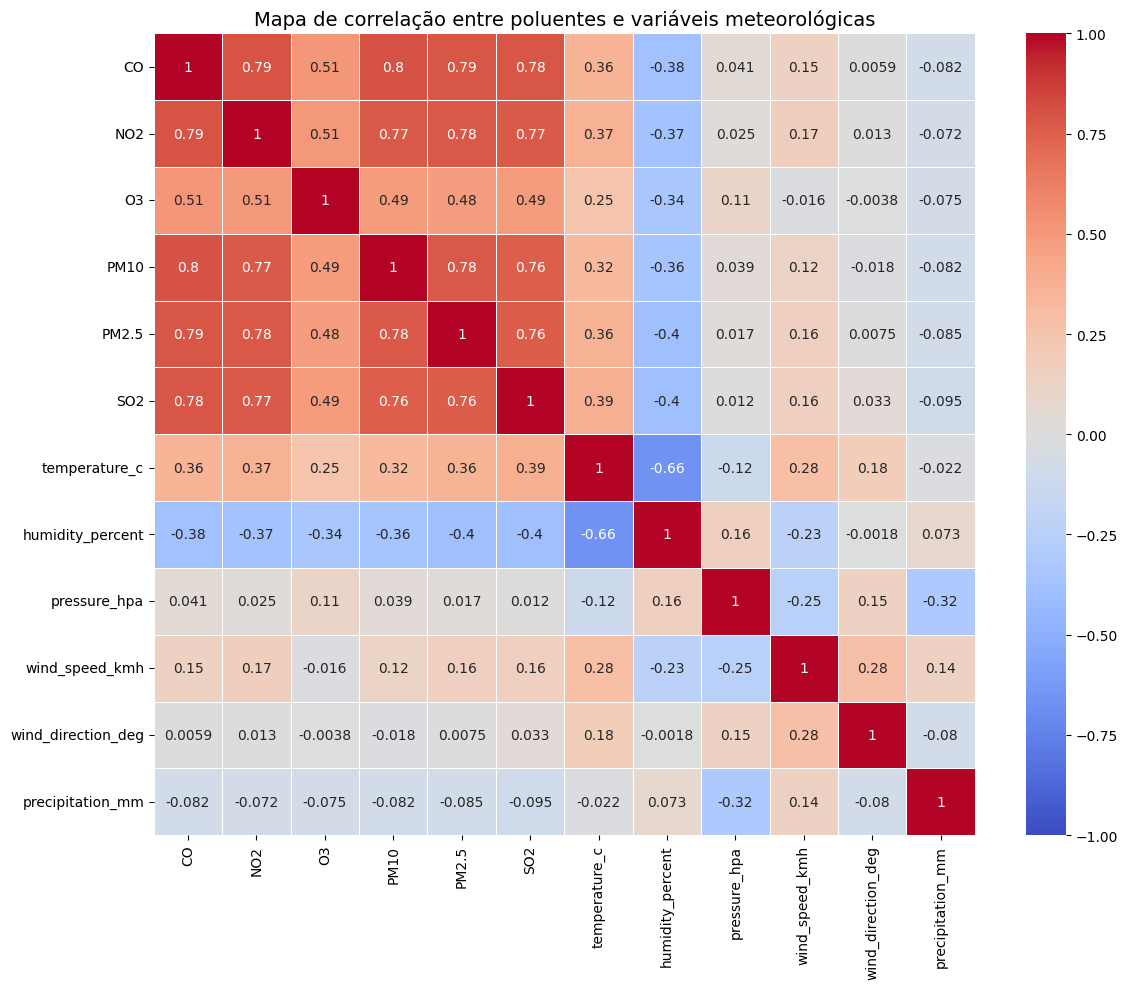

In [11]:
# Correlações
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular correlação apenas para variáveis numéricas
corr = df_eda.corr(numeric_only=True)

# Criar o heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,           # mostra valores de correlação
    cmap="coolwarm",      # cores mais visuais que o 'Blues'
    vmin=-1, vmax=1,      # escala de correlação de -1 a 1
    linewidths=0.5
)

plt.title('Mapa de correlação entre poluentes e variáveis meteorológicas', fontsize=14)
plt.tight_layout()
plt.show()

**🟥 1. Correlação entre poluentes**

Os poluentes CO, NO₂, PM10, PM2.5 e SO₂ apresentam correlações fortes e positivas entre si (valores entre 0.75 e 0.8).
➡️ Interpretação:
Estes poluentes provavelmente têm origem comum, como o tráfego automóvel ou atividades industriais. Quando um aumenta, os outros também tendem a aumentar.
Isto indica que os episódios de má qualidade do ar envolvem múltiplos contaminantes simultaneamente.

**🟦 2. O₃ (ozono)**

O ozono (O₃) tem correlações moderadas positivas com os outros poluentes (~0.5), mas ligeiramente mais fracas.
➡️ Interpretação:
O O₃ é um poluente secundário, formado quimicamente a partir de outros gases (como NO₂ e CO) sob radiação solar.
Como já tinhamos explicado, embora relacionado, o seu comportamento depende também da temperatura e luz solar, não só das emissões diretas.

**🌡️ 3. Temperatura e Humidade**

Temperatura (temperature_c) tem correlação negativa com humidade (-0.66) e ligeiramente negativa com poluentes (-0.3 a -0.4).
➡️ Quando a temperatura aumenta, a humidade tende a diminuir, e certos poluentes podem dispersar mais rapidamente devido à convecção e circulação atmosférica.

Humidade (humidity_percent) mostra correlações negativas com todos os poluentes, especialmente CO e SO₂ (~–0.4).
➡️ Ambientes mais húmidos ajudam a diluir ou lavar partículas da atmosfera, reduzindo concentrações.

**🌬️ 4. Velocidade e direção do vento**

As correlações entre vento (wind_speed_kmh e wind_direction_deg) e poluentes são muito baixas (≈0.1–0.2).
➡️ Interpretação:
O vento tende a dispersar poluentes, mas como varia muito no tempo e espaço, a correlação linear é fraca.
A influência pode ser não linear — ou seja, fortes ventos reduzem poluição, mas brisas leves podem não ter grande efeito.

**🌧️ 5. Precipitação**

A precipitação (precipitation_mm) tem correlação ligeiramente negativa com todos os poluentes (~–0.08 a –0.1).
➡️ Interpretação:
Chuva contribui para a remoção de partículas e gases da atmosfera, mas a correlação fraca indica que o efeito ocorre apenas em eventos pontuais.

**💡 Resumo geral**

Os poluentes estão fortemente interligados → origem comum.

Temperatura e humidade influenciam significativamente a dispersão e concentração dos poluentes.

Vento e chuva ajudam a limpar o ar, mas a correlação linear é mais fraca.

**➡️ Conclusão:**
As condições meteorológicas têm um papel crucial na dispersão e formação dos poluentes, especialmente a humidade e temperatura, que condicionam os níveis de concentração observados.

**🧾 Interpretação do mapa de correlação**

O mapa de correlação mostra relações fortes entre os principais poluentes atmosféricos (CO, NO₂, PM10, PM2.5 e SO₂), com coeficientes acima de 0.75, o que indica uma origem comum, como o tráfego rodoviário e atividades industriais. O ozono (O₃) apresenta correlações moderadas, refletindo a sua formação secundária dependente da radiação solar e da presença de outros gases. Entre as variáveis meteorológicas, a temperatura e a humidade destacam-se: a temperatura está negativamente correlacionada com a humidade (-0.66) e ligeiramente com os poluentes, sugerindo que o aumento da temperatura favorece a dispersão. A humidade, por sua vez, mostra correlação negativa com os poluentes, evidenciando o efeito de diluição e deposição úmida. A velocidade do vento e a precipitação apresentam correlações fracas, mas contribuem para a remoção pontual de poluentes. Em geral, as condições meteorológicas influenciam significativamente a dispersão e formação da poluição atmosférica.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import pandas as pd

### **Pré-processamento - Normalização, Imputação e Split treino/teste**

In [2]:
#Carregar dados e limpar cabeçalhos - Criar o df que vamos usar nos passos seguintes e normalizar nomes de colunas (#, espaços, maiúsculas).

import pandas as pd
from pathlib import Path

# tenta primeiro em data/, se não existir tenta na pasta atual
csv_path = None
for p in [Path("data/combined_Lisboa_porto_complete.csv"),
          Path("combined_Lisboa_porto_complete.csv")]:
    if p.exists():
        csv_path = p
        break

assert csv_path is not None, "Não encontrei o ficheiro CSV. Coloca-o em data/ ou na raiz."

df = pd.read_csv(csv_path, low_memory=False)

# limpar nomes de colunas (#, espaços, maiúsculas, %)
def clean_col(c: str) -> str:
    c = c.strip()
    if c.startswith("#"): c = c[1:].strip()
    return (c.lower()
              .replace("%","percent")
              .replace("º","").replace("°","")
              .replace(" ","_").replace(".","_"))

df.rename(columns={c: clean_col(c) for c in df.columns}, inplace=True)

print("Primeiras colunas:", df.columns.tolist()[:20])
print("Dimensão:", df.shape)


Primeiras colunas: ['city', 'datetime', 'co', 'no2', 'o3', 'pm10', 'pm2_5', 'so2', 'temperature_c', 'humidity_percent', 'pressure_hpa', 'wind_speed_kmh', 'wind_direction_deg', 'precipitation_mm', 'label_air_good']
Dimensão: (1442, 15)


In [4]:
# Definir alvos e preparar uma cópia de trabalho

# === PASSO 1: targets e cópia de trabalho ===
CLASS_TARGET = "label_air_good"   
REG_TARGET   = "no2"              

df_work = df.copy()
assert CLASS_TARGET in df_work.columns, f"Falta coluna {CLASS_TARGET}"
assert REG_TARGET   in df_work.columns, f"Falta coluna {REG_TARGET}"


In [5]:
# Tratar da coluna temporal - extrair hora/dia-da-semana ajuda os modelos e permite split temporal.

# === PASSO 2: features temporais ===
import pandas as pd

if "datetime" in df_work.columns:
    df_work["datetime"] = pd.to_datetime(df_work["datetime"], errors="coerce", utc=True)
    df_work["hour"] = df_work["datetime"].dt.hour
    df_work["dow"]  = df_work["datetime"].dt.dayofweek  # 0=segunda


In [6]:
# Separar X/y e identificar numéricas vs. categóricas
# 0 pré-processamento trata tipos diferentes de forma diferente.

# === PASSO 3: separar features e tipos ===
def split_feature_sets(df_in: pd.DataFrame, target: str):
    X = df_in.drop(columns=[target])
    y = df_in[target].values
    num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat_cols = [c for c in X.columns if c not in num_cols]
    return X, y, num_cols, cat_cols

# classificação
Xc, yc, numc, catc = split_feature_sets(df_work, CLASS_TARGET)
# regressão
Xr, yr, numr, catr = split_feature_sets(df_work, REG_TARGET)

len(numc), len(catc), len(numr), len(catr)


(14, 2, 13, 3)

In [7]:
# Fazer o split treino/teste - testar o modelo em dados “não vistos”
# Como temos datetime, usamos split temporal

# === PASSO 4: split treino/teste ===
from sklearn.model_selection import train_test_split
import numpy as np

def time_split(X, y, ts_col="datetime", test_size=0.2):
    order = np.argsort(pd.to_datetime(X[ts_col], errors="coerce"))
    Xo, yo = X.iloc[order], y[order]
    cut = int((1-test_size) * len(Xo))
    return Xo.iloc[:cut], Xo.iloc[cut:], yo[:cut], yo[cut:]

# classificação
if "datetime" in Xc.columns:
    Xc_tr, Xc_te, yc_tr, yc_te = time_split(Xc, yc, ts_col="datetime", test_size=0.2)
else:
    Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
        Xc, yc, test_size=0.2, random_state=42, stratify=yc
    )

# regressão
if "datetime" in Xr.columns:
    Xr_tr, Xr_te, yr_tr, yr_te = time_split(Xr, yr, ts_col="datetime", test_size=0.2)
else:
    Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
        Xr, yr, test_size=0.2, random_state=42
    )

Xc_tr.shape, Xc_te.shape, Xr_tr.shape, Xr_te.shape


((1153, 16), (289, 16), (1153, 16), (289, 16))

In [9]:
# Pré-processamento (imputação + normalização + one-hot)
# One-hot: processo de transformar variáveis em binário para melhor entendimento pelos algorítmos (regressão logística, SVM, KNN)
# Tratar missing, escalar numéricas e codificar categóricas sem leakage (fit no treino).

# === PASSO 5: pré-processador ===
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def make_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

pre_cls = make_preprocessor(numc, catc)
pre_reg = make_preprocessor(numr, catr)


In [10]:
# Aplicar o pré-processador (fit no treino, transform no teste)
# Porquê? o treino “aprende” imputações/escala/codificação; o teste só recebe a transformação.

# === PASSO 6: transformar treino e teste ===
Xc_tr_p = pre_cls.fit_transform(Xc_tr)
Xc_te_p = pre_cls.transform(Xc_te)

Xr_tr_p = pre_reg.fit_transform(Xr_tr)
Xr_te_p = pre_reg.transform(Xr_te)

Xc_tr_p.shape, Xc_te_p.shape, Xr_tr_p.shape, Xr_te_p.shape


((1153, 593), (289, 593), (1153, 594), (289, 594))

In [12]:
# Validar rapidamente com um baseline
# Porquê? confirmar que o pré-processamento está funcional antes de avançar para os scripts de treino.
# mapear/converter 'No'/'Yes' para 0/1

# === PASSO 7: baseline com labels numéricos 0/1 ===
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error
import numpy as np

# mapear
map_cls = {'No':0, 'Yes':1}
yc_tr_bin = pd.Series(yc_tr).map(map_cls).values
yc_te_bin = pd.Series(yc_te).map(map_cls).values

logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(Xc_tr_p, yc_tr_bin)
yp = logreg.predict(Xc_te_p)

print("CLS - ACC:", accuracy_score(yc_te_bin, yp), "F1:", f1_score(yc_te_bin, yp))  # pos_label=1 por defeito

# regressão (igual)
lin = LinearRegression()
lin.fit(Xr_tr_p, yr_tr)
yh = lin.predict(Xr_te_p)
print("REG - MAE:", mean_absolute_error(yr_te, yh), "RMSE:", np.sqrt(mean_squared_error(yr_te, yh)))



CLS - ACC: 0.7577854671280276 F1: 0.7904191616766467
REG - MAE: 8.615179502826935 RMSE: 10.602050270103819


In [13]:
# guardar pré-processamento

# Deve imprimir shapes e confirmar objetos
print("CLS:", Xc_tr.shape, Xc_te.shape, type(pre_cls).__name__)
print("REG:", Xr_tr.shape, Xr_te.shape, type(pre_reg).__name__)

from pathlib import Path
import joblib
import json

prep_dir = Path("outputs/preprocessing")
prep_dir.mkdir(parents=True, exist_ok=True)

# 1) Guardar preprocessadores já 'fit' (imputação + scaler + one-hot)
joblib.dump(pre_cls, prep_dir / "pre_cls.joblib")
joblib.dump(pre_reg, prep_dir / "pre_reg.joblib")

# 2) Guardar índices dos splits (para replicar exatamente no treino)
split_info = {
    "classification": {
        "train_idx": Xc_tr.index.tolist(),
        "test_idx":  Xc_te.index.tolist()
    },
    "regression": {
        "train_idx": Xr_tr.index.tolist(),
        "test_idx":  Xr_te.index.tolist()
    }
}
with open(prep_dir / "splits.json", "w", encoding="utf-8") as f:
    json.dump(split_info, f, ensure_ascii=False, indent=2)

# 3) Guardar info útil (nomes de colunas, mapeamento do y binário se usaste 0/1)
prep_meta = {
    "num_cols_cls": numc,
    "cat_cols_cls": catc,
    "num_cols_reg": numr,
    "cat_cols_reg": catr,
    "class_mapping_example": {"No": 0, "Yes": 1}  # ajusta se usares outro mapping
}
with open(prep_dir / "meta.json", "w", encoding="utf-8") as f:
    json.dump(prep_meta, f, ensure_ascii=False, indent=2)

print("Pré-processamento guardado em:", prep_dir)


CLS: (1153, 16) (289, 16) ColumnTransformer
REG: (1153, 16) (289, 16) ColumnTransformer
Pré-processamento guardado em: outputs\preprocessing
